# **Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
import plotly.graph_objects as go # Plotly module for interactive scientific graphics

# **Microscopic semi-phenomenological model of Doppler absorption in rubidium**

## **1. Physical picture**

Optical absorption in rubidium vapor arises from the interaction between the incident electromagnetic field and the induced atomic polarization.

The optical response of the medium can be described by the complex susceptibility

$$
\chi(\omega)=\chi'(\omega)+i\chi''(\omega).
$$

where

* $\chi'(\omega)$ describes dispersion,
* $\chi''(\omega)$ describes absorption.

The measured optical absorption is proportional to the imaginary part of the susceptibility:

$$
A(\omega)\propto \mathrm{Im}!\left[\chi(\omega)\right].
$$

---

## **2. Doppler broadening**

Thermal atomic motion causes each velocity class to experience a different optical frequency through the Doppler effect:

$$
\omega'=\omega-kv,
$$

where

* $\omega$ is the laser frequency,
* $k$ is the optical wave number,
* $v$ is the atomic velocity.

Different velocity classes therefore resonate at slightly different frequencies, producing inhomogeneous spectral broadening.

---

## **3. Velocity distribution**

Atomic velocities follow a Maxwell–Boltzmann distribution:

$$
f(v)=
\sqrt{\frac{m}{2\pi k_B T}}
\exp\left(-\frac{mv^2}{2k_B T}\right),
$$

where

* $m$ is the effective atomic mass,
* $k_B$ is the Boltzmann constant,
* $T$ is the absolute temperature.

---

## **4. Susceptibility of an optical transition**

For a resonant transition, the susceptibility associated with one velocity class is modeled as

$$
\chi(\omega,v)\propto
\frac{1}{\omega-\omega_0-kv+i\gamma},
$$

where

* $\omega_0$ is the transition frequency,
* $\gamma$ is the homogeneous linewidth.

---

## **5. Doppler-broadened susceptibility**

The total susceptibility of a transition is obtained by integrating over all atomic velocities:

$$
\chi_D(\omega)=
\int_{-\infty}^{\infty}
dv,f(v)
\frac{1}{\omega-\omega_0-kv+i\gamma}.
$$

This expression includes

* homogeneous broadening,
* Doppler broadening,
* the thermal velocity distribution,
* the microscopic optical response.

---

## **6. Multiple hyperfine contributions**

The experimental spectrum contains several resonances associated with different hyperfine transitions.

The total susceptibility is therefore modeled as

$$
\chi_{\mathrm{tot}}(\omega)=
\sum_i A_i,\chi_i(\omega),
$$

where

$$
\chi_i(\omega)=
\int_{-\infty}^{\infty}
dv,f(v)
\frac{1}{\omega-\omega_i-kv+i\gamma}.
$$

The parameters are

* $\omega_i$: effective resonance positions,
* $A_i$: effective relative amplitudes.

The final absorption is calculated as

$$
A(\omega)\propto
\mathrm{Im}
\left[
\chi_{\mathrm{tot}}(\omega)
\right].
$$

---

## **7. Physical parameters**

### **Temperature**

The value used is

$$
T=293\ \mathrm{K},
$$

approximately room temperature.

### **Optical line**

The rubidium D2 line is used:

$$
\lambda_0=780\ \mathrm{nm}.
$$

The associated optical frequency is

$$
\nu_0=\frac{c}{\lambda_0}.
$$

### **Homogeneous broadening**

The value used is

$$
\gamma=2\pi\times6\ \mathrm{MHz},
$$

approximately the natural linewidth of the D2 transition.

---

## **8. Effective hyperfine positions**

The initial resonance positions are

$$
\Omega_{87}^{(\mathrm{th})}=(-5.2,;2.2)\ \mathrm{GHz},
$$

$$
\Omega_{85}^{(\mathrm{th})}=(-1.8,;1.0)\ \mathrm{GHz}.
$$

Phenomenological corrections improve agreement with the digitized experimental spectrum:

$$
\delta_{87}=(0.60,;0.00)\ \mathrm{GHz},
$$

$$
\delta_{85}=(-0.25,;0.00)\ \mathrm{GHz}.
$$

The final effective positions are obtained from

$$
\Omega_i=\Omega_i^{(\mathrm{th})}+\delta_i.
$$

---

## **9. Effective relative intensities**

The relative amplitudes are

$$
A_i=(0.10,;0.28,;1.00,;0.45).
$$

These parameters were fitted phenomenologically to reproduce the observed relative intensities.

---

## **10. Global shift**

A global horizontal shift is introduced:

$$
\Omega\rightarrow\Omega+\Delta,
$$

with

$$
\Delta=0.348\ \mathrm{GHz},
$$

to correct the residual offset between the digitized experimental scale and the theoretical model.

---

## **11. Physical interpretation**

The implemented model is a microscopic, semi-phenomenological description of the absorption spectrum.

Microscopic physics is incorporated through

* complex susceptibility,
* homogeneous broadening,
* Doppler broadening,
* integration over the Maxwell–Boltzmann distribution.

Resonance positions and intensities are fitted phenomenologically to reproduce the observed experimental structure.

---

## **12. Model limitations**

The model does not explicitly include

* optical Bloch equations,
* Clebsch–Gordan coefficients,
* ab initio hyperfine structure,
* Zeeman structure,
* optical saturation,
* optical pumping,
* full density-matrix dynamics.

The model captures the dominant absorption-spectrum physics but is not a complete *ab initio* simulation of the rubidium atom.

---

## **13. Reference**

Jian Ma et al.

*Optical spin noise spectra of Rb atomic gas with homogeneous and inhomogeneous broadening*.

Scientific Reports **7**, 10238 (2017).

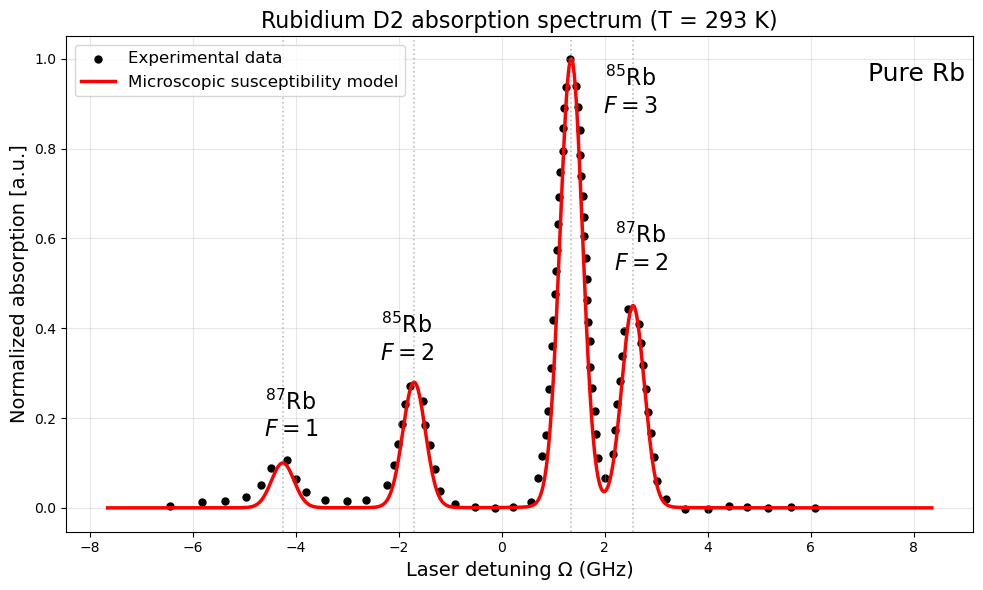

In [2]:
# ============================================================
# Microscopic Doppler-broadened susceptibility model
# for Rubidium D2 absorption spectrum
#
# Multiple hyperfine transitions
#
# ============================================================
# PHYSICAL CONSTANTS
# ============================================================

# Speed of light [m/s]
c = 3.0e8

# Boltzmann constant [J/K]
kB = 1.380649e-23

# Atomic mass unit [kg]
amu = 1.660539e-27

# Rubidium-85 atomic mass [kg]
m_Rb = 85 * amu


# ============================================================
# RUBIDIUM D2 TRANSITION
# ============================================================

# D2 wavelength [m]
lambda0 = 780e-9

# Optical frequency [Hz]
nu0 = c / lambda0

# Optical angular frequency [rad/s]
omega0 = 2*np.pi*nu0


# ============================================================
# TEMPERATURE
# ============================================================

# Temperature [K]
T = 293


# ============================================================
# HOMOGENEOUS LINEWIDTH
# ============================================================

# Natural linewidth [rad/s]
gamma = 2*np.pi*6e6


# ============================================================
# WAVEVECTOR
# ============================================================

# Optical wavevector [1/m]
k = 2*np.pi / lambda0


# ============================================================
# VELOCITY GRID
# ============================================================

# Atomic velocities [m/s]
v = np.linspace(
    -1500,
     1500,
     4000
)


# ============================================================
# MAXWELL-BOLTZMANN DISTRIBUTION
# ============================================================

fv = np.sqrt(
    m_Rb / (2*np.pi*kB*T)
)

fv *= np.exp(
    -m_Rb*v**2 / (2*kB*T)
)


# ============================================================
# DETUNING AXIS
# ============================================================

Delta_GHz = np.linspace(
    -8,
     8,
     3000
)

Delta = 2*np.pi*Delta_GHz*1e9


# ============================================================
# THEORETICAL HYPERFINE POSITIONS
# ============================================================

centers87_theory = np.array([
    -5.2,
     2.2
])

centers85_theory = np.array([
    -1.8,
     1.0
])


# ============================================================
# EFFECTIVE POSITION CORRECTIONS
# ============================================================

delta87 = np.array([
    0.6,
    0.00
])

delta85 = np.array([
   -0.25,
    0.00
])


# ============================================================
# EFFECTIVE PEAK POSITIONS
# ============================================================

centers87 = centers87_theory + delta87
centers85 = centers85_theory + delta85


# ============================================================
# COMBINED POSITIONS
# ============================================================

centers_GHz = np.array([
    centers87[0],
    centers85[0],
    centers85[1],
    centers87[1]
])


# ============================================================
# RELATIVE AMPLITUDES
# ============================================================

amplitudes = np.array([
    0.10,
    0.28,
    1.00,
    0.45
])


# ============================================================
# TOTAL SUSCEPTIBILITY
# ============================================================

chi_total = np.zeros_like(
    Delta,
    dtype=complex
)


# ============================================================
# BUILD MICROSCOPIC MODEL
# ============================================================

for A, center in zip(amplitudes, centers_GHz):

    center_rad = 2*np.pi*center*1e9

    chi_i = np.zeros_like(
        Delta,
        dtype=complex
    )

    for j, d in enumerate(Delta):

        denominator = (
            d - center_rad - k*v + 1j*gamma
        )

        integrand = fv / denominator

        chi_i[j] = simpson(
            integrand,
            v
        )

    chi_total += A * chi_i


# ============================================================
# ABSORPTION
# ============================================================

Absorption = np.abs(
    np.imag(chi_total)
)

Absorption /= np.max(
    Absorption
)


# ============================================================
# LOAD EXPERIMENTAL DATA
# ============================================================

data = np.loadtxt(
    "Data_Rb_Gas.csv",
    delimiter=",",
    skiprows=1
)

x_exp = data[:,0]
y_exp = data[:,1]

y_exp /= np.max(y_exp)


# ============================================================
# GLOBAL SHIFT
# ============================================================

shift = 0.348

Delta_shifted = Delta_GHz + shift


# ============================================================
# FIGURE
# ============================================================

plt.figure(
    figsize=(10,6)
)


# ============================================================
# EXPERIMENTAL DATA
# ============================================================

plt.scatter(
    x_exp,
    y_exp,
    color='black',
    s=25,
    label='Experimental data'
)


# ============================================================
# MICROSCOPIC MODEL
# ============================================================

plt.plot(
    Delta_shifted,
    Absorption,
    color='red',
    linewidth=2.5,
    label='Microscopic susceptibility model'
)


# ============================================================
# RESONANCE POSITIONS
# ============================================================

for center in centers_GHz + shift:

    plt.axvline(
        center,
        color='gray',
        linestyle=':',
        linewidth=1.2,
        alpha=0.5
    )


# ============================================================
# HYPERFINE LABELS
# ============================================================

plt.text(
    -4.1,
    0.16,
    r'$^{87}\mathrm{Rb}$'+'\n'+r'$F=1$',
    fontsize=16,
    ha='center'
)

plt.text(
    -1.85,
    0.33,
    r'$^{85}\mathrm{Rb}$'+'\n'+r'$F=2$',
    fontsize=16,
    ha='center'
)

plt.text(
    2.5,
    0.88,
    r'$^{85}\mathrm{Rb}$'+'\n'+r'$F=3$',
    fontsize=16,
    ha='center'
)

plt.text(
    2.7,
    0.53,
    r'$^{87}\mathrm{Rb}$'+'\n'+r'$F=2$',
    fontsize=16,
    ha='center'
)


# ============================================================
# SAMPLE LABEL
# ============================================================

plt.text(
    7.1,
    0.95,
    'Pure Rb',
    fontsize=18
)


# ============================================================
# STYLE
# ============================================================

plt.xlabel(
    'Laser detuning Ω (GHz)',
    fontsize=14
)

plt.ylabel(
    'Normalized absorption [a.u.]',
    fontsize=14
)

plt.title(
    f'Rubidium D2 absorption spectrum (T = {T} K)',
    fontsize=16
)

plt.grid(alpha=0.3)

plt.legend(
    fontsize=12,
    loc='upper left'
)

plt.tight_layout()

plt.show()

### **Difference between experiment and theory**

The lower panel shows the difference between the experimental spectrum and the fitted Gaussian Doppler model.

The theoretical spectrum is interpolated onto the experimental grid, after which the residual is calculated:

$$
R(\Omega)=A_{\mathrm{exp}}-A_{\mathrm{model}}
$$

The difference is multiplied by 100 to highlight small discrepancies between theory and experiment.

Values close to zero indicate good agreement between the model and experimental data.

# **Fit-quality metrics**

The mean squared error (MSE) and mean absolute error (MAE) quantify agreement between the theoretical model and experimental data.

Let

$$
y_i
$$

denote an experimental value and

$$
\hat y(x_i)
$$

the model prediction evaluated at the same point.

The MSE is defined as

$$
\mathrm{MSE}=

\frac{1}{N}
\sum_{i=1}^{N}
\left(
\hat y(x_i)-y_i
\right)^2
$$

while the MAE is

$$
\mathrm{MAE}=

\frac{1}{N}
\sum_{i=1}^{N}
\left|
\hat y(x_i)-y_i
\right|
$$

Both metrics quantify discrepancies between theory and experiment. Values closer to zero indicate a better fit to the experimental data.


MICROSCOPIC MODEL
MSE = 0.004004
MAE = 0.048501


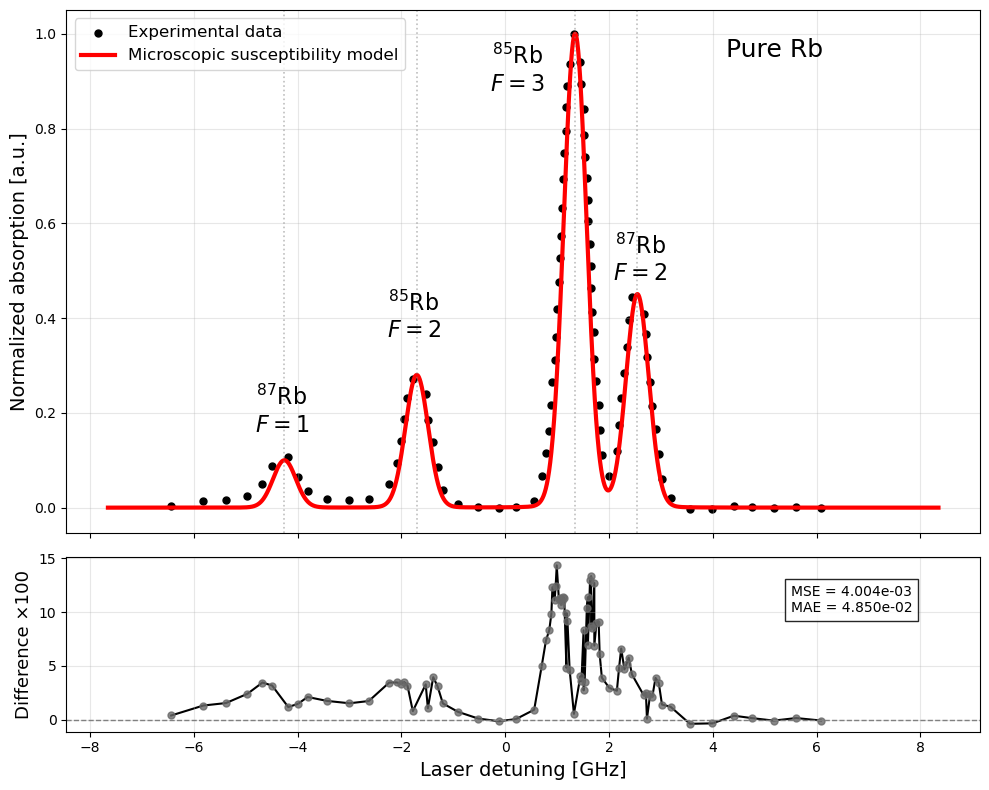

In [3]:
# ============================================================
# THEORY–EXPERIMENT COMPARISON
#
# Uses:
#
#   x_exp
#   y_exp
#   Delta_shifted
#   Absorption
#
# already generated by the main model
#
# ============================================================


# ============================================================
# INTERPOLATE MODEL ON EXPERIMENTAL GRID
# ============================================================

Abs_interp = np.interp(

    x_exp,
    Delta_shifted,
    Absorption
)


# ============================================================
# DIFFERENCE
#
# Difference = experimental - theoretical
# ============================================================

Difference = 100 * (y_exp - Abs_interp)


# ============================================================
# MODEL QUALITY METRICS
#
# Microscopic susceptibility model
# ============================================================

MSE = np.mean(
    (Abs_interp - y_exp)**2
)

MAE = np.mean(
    np.abs(Abs_interp - y_exp)
)

print()
print("================================")
print("MICROSCOPIC MODEL")
print("================================")
print(f"MSE = {MSE:.6f}")
print(f"MAE = {MAE:.6f}")
print("================================")


# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(

    2,
    1,

    figsize=(10,8),

    sharex=True,

    gridspec_kw={
        'height_ratios': [3,1]
    }
)


# ============================================================
# TOP PANEL
#
# Experimental spectrum + microscopic model
# ============================================================

ax1.scatter(

    x_exp,
    y_exp,

    color='black',
    s=25,

    label='Experimental data'
)


ax1.plot(

    Delta_shifted,
    Absorption,

    color='red',
    linewidth=3,

    label='Microscopic susceptibility model'
)


# ============================================================
# RESONANCE POSITIONS
# ============================================================

for center in centers_GHz + shift:

    ax1.axvline(

        center,

        color='gray',

        linestyle=':',

        linewidth=1.2,

        alpha=0.5
    )


# ============================================================
# HYPERFINE LABELS
# ============================================================

ax1.text(
    -4.3,
    0.16,
    r'$^{87}\mathrm{Rb}$' + '\n' + r'$F=1$',
    fontsize=16,
    ha='center'
)

ax1.text(
    -1.76,
    0.36,
    r'$^{85}\mathrm{Rb}$' + '\n' + r'$F=2$',
    fontsize=16,
    ha='center'
)

ax1.text(
    0.24,
    0.88,
    r'$^{85}\mathrm{Rb}$' + '\n' + r'$F=3$',
    fontsize=16,
    ha='center'
)

ax1.text(
    2.6,
    0.48,
    r'$^{87}\mathrm{Rb}$' + '\n' + r'$F=2$',
    fontsize=16,
    ha='center'
)


# ============================================================
# SAMPLE LABEL
# ============================================================

ax1.text(
    4.25,
    0.95,
    'Pure Rb',
    fontsize=18
)


# ============================================================
# TOP PANEL STYLE
# ============================================================

ax1.set_ylabel(
    'Normalized absorption [a.u.]',
    fontsize=14
)

ax1.grid(alpha=0.3)

ax1.legend(
    fontsize=12,
    loc='upper left'
)


# ============================================================
# BOTTOM PANEL
#
# Difference curve
# ============================================================

# Trend

ax2.plot(

    x_exp,
    Difference,

    color='black',

    linewidth=1.5,

    zorder=1
)

# Experimental points

ax2.scatter(

    x_exp,
    Difference,

    color='dimgray',

    s=25,

    alpha=0.8,

    zorder=2
)


# ============================================================
# MSE / MAE BOX
# ============================================================

ax2.text(

    5.5,
    10,

    f"MSE = {MSE:.3e}\nMAE = {MAE:.3e}",

    fontsize=10,

    bbox=dict(
        facecolor='white',
        alpha=0.85
    )
)


# ============================================================
# ZERO LINE
# ============================================================

ax2.axhline(

    0,

    color='gray',

    linestyle='--',

    linewidth=1
)


# ============================================================
# BOTTOM PANEL STYLE
# ============================================================

ax2.set_xlabel(
    'Laser detuning [GHz]',
    fontsize=14
)

ax2.set_ylabel(
    'Difference ×100',
    fontsize=13
)

ax2.grid(alpha=0.3)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()

plt.show()

# **Seminar code**


MICROSCOPIC MODEL
MSE = 0.004004
MAE = 0.048501


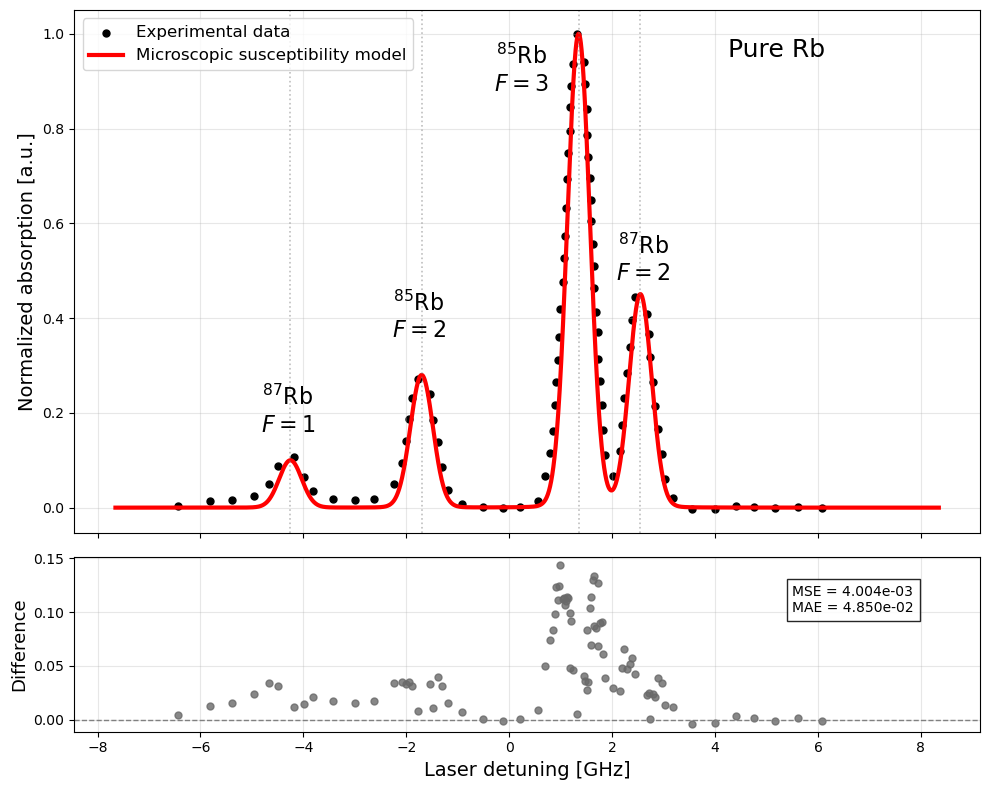

In [5]:
# ============================================================
# THEORY–EXPERIMENT COMPARISON
#
# Uses:
#
#   x_exp
#   y_exp
#   Delta_shifted
#   Absorption
#
# already generated by the main model
#
# ============================================================


# ============================================================
# INTERPOLATE MODEL ON EXPERIMENTAL GRID
# ============================================================

Abs_interp = np.interp(

    x_exp,
    Delta_shifted,
    Absorption
)


# ============================================================
# DIFFERENCE
#
# Difference = experimental - theoretical
# ============================================================

Difference = 1 * (y_exp - Abs_interp)


# ============================================================
# MODEL QUALITY METRICS
#
# Microscopic susceptibility model
# ============================================================

MSE = np.mean(
    (Abs_interp - y_exp)**2
)

MAE = np.mean(
    np.abs(Abs_interp - y_exp)
)

print()
print("================================")
print("MICROSCOPIC MODEL")
print("================================")
print(f"MSE = {MSE:.6f}")
print(f"MAE = {MAE:.6f}")
print("================================")


# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(

    2,
    1,

    figsize=(10,8),

    sharex=True,

    gridspec_kw={
        'height_ratios': [3,1]
    }
)


# ============================================================
# TOP PANEL
#
# Experimental spectrum + microscopic model
# ============================================================

ax1.scatter(

    x_exp,
    y_exp,

    color='black',
    s=25,

    label='Experimental data'
)


ax1.plot(

    Delta_shifted,
    Absorption,

    color='red',
    linewidth=3,

    label='Microscopic susceptibility model'
)


# ============================================================
# RESONANCE POSITIONS
# ============================================================

for center in centers_GHz + shift:

    ax1.axvline(

        center,

        color='gray',

        linestyle=':',

        linewidth=1.2,

        alpha=0.5
    )


# ============================================================
# HYPERFINE LABELS
# ============================================================

ax1.text(
    -4.3,
    0.16,
    r'$^{87}\mathrm{Rb}$' + '\n' + r'$F=1$',
    fontsize=16,
    ha='center'
)

ax1.text(
    -1.76,
    0.36,
    r'$^{85}\mathrm{Rb}$' + '\n' + r'$F=2$',
    fontsize=16,
    ha='center'
)

ax1.text(
    0.24,
    0.88,
    r'$^{85}\mathrm{Rb}$' + '\n' + r'$F=3$',
    fontsize=16,
    ha='center'
)

ax1.text(
    2.6,
    0.48,
    r'$^{87}\mathrm{Rb}$' + '\n' + r'$F=2$',
    fontsize=16,
    ha='center'
)


# ============================================================
# SAMPLE LABEL
# ============================================================

ax1.text(
    4.25,
    0.95,
    'Pure Rb',
    fontsize=18
)


# ============================================================
# TOP PANEL STYLE
# ============================================================

ax1.set_ylabel(
    'Normalized absorption [a.u.]',
    fontsize=14
)

ax1.grid(alpha=0.3)

ax1.legend(
    fontsize=12,
    loc='upper left'
)


# ============================================================
# BOTTOM PANEL
#
# Difference curve
# ============================================================

# Experimental points

ax2.scatter(

    x_exp,
    Difference,

    color='dimgray',

    s=25,

    alpha=0.8,

    zorder=2
)


# ============================================================
# MSE / MAE BOX
# ============================================================

ax2.text(

    5.5,
    0.1,

    f"MSE = {MSE:.3e}\nMAE = {MAE:.3e}",

    fontsize=10,

    bbox=dict(
        facecolor='white',
        alpha=0.85
    )
)


# ============================================================
# ZERO LINE
# ============================================================

ax2.axhline(

    0,

    color='gray',

    linestyle='--',

    linewidth=1
)


# ============================================================
# BOTTOM PANEL STYLE
# ============================================================

ax2.set_xlabel(
    'Laser detuning [GHz]',
    fontsize=14
)

ax2.set_ylabel(
    'Difference',
    fontsize=13
)

ax2.grid(alpha=0.3)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()

plt.show()

### **INTERACTIVE RUBIDIUM ABSORPTION SPECTRUM**

In [4]:
# ============================================================
# INTERACTIVE microscopic Doppler-broadened susceptibility model
# for Rubidium D2 absorption spectrum
#
# Features:
# - interactive zoom
# - pan
# - hover coordinates
# - high-resolution visualization
# - export to PNG/PDF/SVG
#
# ============================================================
# Microscopic Doppler-broadened susceptibility model
# for Rubidium D2 absorption spectrum
#
# Multiple hyperfine transitions
#
# ============================================================
# PHYSICAL CONSTANTS
# ============================================================

# Speed of light [m/s]
c = 3.0e8

# Boltzmann constant [J/K]
kB = 1.380649e-23

# Atomic mass unit [kg]
amu = 1.660539e-27

# Rubidium-85 atomic mass [kg]
m_Rb = 85 * amu


# ============================================================
# RUBIDIUM D2 TRANSITION
# ============================================================

# D2 wavelength [m]
lambda0 = 780e-9

# Optical frequency [Hz]
nu0 = c / lambda0

# Optical angular frequency [rad/s]
omega0 = 2*np.pi*nu0


# ============================================================
# TEMPERATURE
# ============================================================

# Temperature [K]
T = 293


# ============================================================
# HOMOGENEOUS LINEWIDTH
# ============================================================

# Natural linewidth [rad/s]
gamma = 2*np.pi*6e6


# ============================================================
# WAVEVECTOR
# ============================================================

# Optical wavevector [1/m]
k = 2*np.pi / lambda0


# ============================================================
# VELOCITY GRID
# ============================================================

# Atomic velocities [m/s]
v = np.linspace(
    -1500,
     1500,
     4000
)


# ============================================================
# MAXWELL-BOLTZMANN DISTRIBUTION
# ============================================================

fv = np.sqrt(
    m_Rb / (2*np.pi*kB*T)
)

fv *= np.exp(
    -m_Rb*v**2 / (2*kB*T)
)


# ============================================================
# DETUNING AXIS
# ============================================================

Delta_GHz = np.linspace(
    -8,
     8,
     3000
)

Delta = 2*np.pi*Delta_GHz*1e9


# ============================================================
# THEORETICAL HYPERFINE POSITIONS
# ============================================================

centers87_theory = np.array([
    -5.2,
     2.2
])

centers85_theory = np.array([
    -1.8,
     1.0
])


# ============================================================
# EFFECTIVE POSITION CORRECTIONS
# ============================================================

delta87 = np.array([
    0.6,
    0.00
])

delta85 = np.array([
   -0.25,
    0.00
])


# ============================================================
# EFFECTIVE PEAK POSITIONS
# ============================================================

centers87 = centers87_theory + delta87
centers85 = centers85_theory + delta85


# ============================================================
# COMBINED POSITIONS
# ============================================================

centers_GHz = np.array([
    centers87[0],
    centers85[0],
    centers85[1],
    centers87[1]
])


# ============================================================
# RELATIVE AMPLITUDES
# ============================================================

amplitudes = np.array([
    0.10,
    0.28,
    1.00,
    0.45
])


# ============================================================
# TOTAL SUSCEPTIBILITY
# ============================================================

chi_total = np.zeros_like(
    Delta,
    dtype=complex
)


# ============================================================
# BUILD MICROSCOPIC MODEL
# ============================================================

for A, center in zip(amplitudes, centers_GHz):

    center_rad = 2*np.pi*center*1e9

    chi_i = np.zeros_like(
        Delta,
        dtype=complex
    )

    for j, d in enumerate(Delta):

        denominator = (
            d - center_rad - k*v + 1j*gamma
        )

        integrand = fv / denominator

        chi_i[j] = simpson(
            integrand,
            v
        )

    chi_total += A * chi_i


# ============================================================
# ABSORPTION
# ============================================================

Absorption = np.abs(
    np.imag(chi_total)
)

Absorption /= np.max(
    Absorption
)


# ============================================================
# LOAD EXPERIMENTAL DATA
# ============================================================

data = np.loadtxt(
    "Data_Rb_Gas.csv",
    delimiter=",",
    skiprows=1
)

x_exp = data[:,0]
y_exp = data[:,1]

y_exp /= np.max(y_exp)


# ============================================================
# GLOBAL SHIFT
# ============================================================

shift = 0.348

Delta_shifted = Delta_GHz + shift


# ============================================================
# INTERACTIVE FIGURE
# ============================================================

import plotly.graph_objects as go

fig = go.Figure()


# ============================================================
# EXPERIMENTAL DATA
# ============================================================

fig.add_trace(

    go.Scatter(

        x=x_exp,
        y=y_exp,

        mode='markers',

        name='Experimental data',

        marker=dict(
            color='black',
            size=6
        )
    )
)


# ============================================================
# MICROSCOPIC MODEL
# ============================================================

fig.add_trace(

    go.Scatter(

        x=Delta_shifted,
        y=Absorption,

        mode='lines',

        name='Microscopic susceptibility model',

        line=dict(
            color='red',
            width=3
        )
    )
)


# ============================================================
# RESONANCE POSITIONS
# ============================================================

for center in centers_GHz + shift:

    fig.add_vline(

        x=center,

        line_dash='dot',

        line_color='gray',

        opacity=0.5
    )


# ============================================================
# HYPERFINE LABELS
# ============================================================

fig.add_annotation(
    x=-4.1,
    y=0.16,
    text='87Rb<br>F=1',
    showarrow=False,
    font=dict(size=18)
)

fig.add_annotation(
    x=-1.85,
    y=0.33,
    text='85Rb<br>F=2',
    showarrow=False,
    font=dict(size=18)
)

fig.add_annotation(
    x=2.5,
    y=0.88,
    text='85Rb<br>F=3',
    showarrow=False,
    font=dict(size=18)
)

fig.add_annotation(
    x=2.7,
    y=0.53,
    text='87Rb<br>F=2',
    showarrow=False,
    font=dict(size=18)
)


# ============================================================
# SAMPLE LABEL
# ============================================================

fig.add_annotation(
    x=7.1,
    y=0.95,
    text='Pure Rb',
    showarrow=False,
    font=dict(size=22)
)


# ============================================================
# LAYOUT
# ============================================================

fig.update_layout(

    title=f'Rubidium D2 absorption spectrum (T = {T} K)',

    xaxis_title='Laser detuning Ω (GHz)',

    yaxis_title='Normalized absorption [a.u.]',

    template='plotly_white',

    width=1000,
    height=600,

    font=dict(size=16),

    xaxis=dict(
        showgrid=True,
        zeroline=False
    ),

    yaxis=dict(
        range=[-0.05,1.05],
        showgrid=True,
        zeroline=False
    ),

    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255,255,255,0.8)'
    )
)


# ============================================================
# SHOW FIGURE
# ============================================================

fig.show()
# ============================================================
# OPTIONAL EXPORTS
# ============================================================

# fig.write_image("Rubidium_spectrum.png")
# fig.write_image("Rubidium_spectrum.pdf")
# fig.write_image("Rubidium_spectrum.svg")
# fig.write_html("Rubidium_spectrum.html")